IMPORT LEBRARY

In [18]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.tree import plot_tree

Load dataset

In [19]:
df_laundry = pd.read_csv("dataset_laundry.csv")

print("Lima data pertama:")
print(df_laundry.head())

print("\nInformasi dataset:")
df_laundry.info()

print("\nJumlah data kosong:")
print(df_laundry.isnull().sum())

Lima data pertama:
    kg  sabun  parfum
0  2.5     50     0.5
1  7.5    150     1.5
2  6.5    130     1.3
3  6.0    120     1.2
4  7.5    150     1.5

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 495 entries, 0 to 494
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   kg      495 non-null    float64
 1   sabun   495 non-null    int64  
 2   parfum  495 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 11.7 KB

Jumlah data kosong:
kg        0
sabun     0
parfum    0
dtype: int64


Menapilkan isi Target

In [20]:
df_laundry['kg'].value_counts()

kg
7.5     35
8.0     35
5.5     32
8.5     32
4.5     31
5.0     30
9.5     29
10.0    28
6.0     28
2.0     27
7.0     24
4.0     24
1.0     24
2.5     23
3.5     20
1.5     20
9.0     19
3.0     19
6.5     15
Name: count, dtype: int64

Pilih Coloum penting

In [21]:
# kolom_wajib = ["kg", "sabun", "parfum"]

# for kolom in kolom_wajib:
#     if kolom not in df_laundry.columns:
#         raise ValueError(
#             f"Kolom '{kolom}' tidak ditemukan dalam dataset."
#         )

In [22]:

df_laundry = pd.read_csv("dataset_laundry.csv")

print("Lima data pertama:")
print(df_laundry.head())

print("\nInformasi dataset:")
df_laundry.info()

print("\nJumlah data kosong:")
print(df_laundry.isnull().sum())

Lima data pertama:
    kg  sabun  parfum
0  2.5     50     0.5
1  7.5    150     1.5
2  6.5    130     1.3
3  6.0    120     1.2
4  7.5    150     1.5

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 495 entries, 0 to 494
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   kg      495 non-null    float64
 1   sabun   495 non-null    int64  
 2   parfum  495 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 11.7 KB

Jumlah data kosong:
kg        0
sabun     0
parfum    0
dtype: int64


Encode RainToday & RainTomorow (Yes/No - 0/1)

In [23]:
kolom_wajib = ["kg", "sabun", "parfum"]

for kolom in kolom_wajib:
    if kolom not in df_laundry.columns:
        raise ValueError(
            f"Kolom '{kolom}' tidak ditemukan dalam dataset."
        )

data = df_laundry[kolom_wajib].copy()

for kolom in kolom_wajib:
    data[kolom] = pd.to_numeric(
        data[kolom], errors="coerce"
    )

data = data.dropna()

# Berat cucian harus lebih dari 0 dan maksimal 10 kg.
data = data[
    (data["kg"] > 0) &
    (data["kg"] <= 10)
]

if len(data) < 5:
    raise ValueError(
        "Data valid terlalu sedikit untuk training."
    )

print("\nJumlah data valid:", len(data))
print("\nDistribusi berat cucian:")
print(data["kg"].value_counts().sort_index())


Jumlah data valid: 495

Distribusi berat cucian:
kg
1.0     24
1.5     20
2.0     27
2.5     23
3.0     19
3.5     20
4.0     24
4.5     31
5.0     30
5.5     32
6.0     28
6.5     15
7.0     24
7.5     35
8.0     35
8.5     32
9.0     19
9.5     29
10.0    28
Name: count, dtype: int64


Split Fitur & Target

In [24]:

# INPUT: berat cucian
X = data[["kg"]]

# TARGET: kebutuhan sabun dan parfum
y = data[["sabun", "parfum"]]

print("\nFitur input:")
print(X.head())

print("\nTarget prediksi:")
print(y.head())


Fitur input:
    kg
0  2.5
1  7.5
2  6.5
3  6.0
4  7.5

Target prediksi:
   sabun  parfum
0     50     0.5
1    150     1.5
2    130     1.3
3    120     1.2
4    150     1.5


Split fitur & Target

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))


Jumlah data training: 396
Jumlah data testing: 99


Training Model random forest

In [26]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nModel Random Forest berhasil dilatih.")


Model Random Forest berhasil dilatih.


Prdiksi

In [27]:
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "kg": X_test["kg"].to_numpy(),
    "sabun_aktual": y_test["sabun"].to_numpy(),
    "sabun_prediksi": y_pred[:, 0],
    "parfum_aktual": y_test["parfum"].to_numpy(),
    "parfum_prediksi": y_pred[:, 1]
})

print("\nHasil prediksi:")
print(hasil_prediksi.head(10))


Hasil prediksi:
    kg  sabun_aktual  sabun_prediksi  parfum_aktual  parfum_prediksi
0  3.5            70            70.0            0.7              0.7
1  7.0           140           140.0            1.4              1.4
2  6.0           120           120.0            1.2              1.2
3  6.0           120           120.0            1.2              1.2
4  1.5            30            30.0            0.3              0.3
5  8.0           160           160.0            1.6              1.6
6  7.0           140           140.0            1.4              1.4
7  5.5           110           110.0            1.1              1.1
8  5.5           110           110.0            1.1              1.1
9  4.0            80            80.0            0.8              0.8


Evaluasi Model

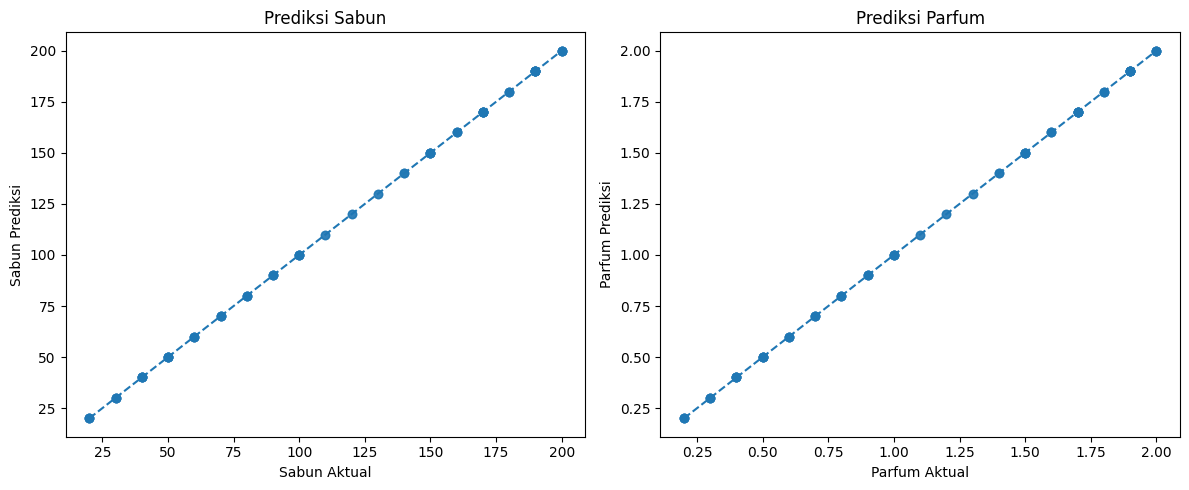

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, target in enumerate(["sabun", "parfum"]):
    aktual = y_test[target].to_numpy()
    prediksi = y_pred[:, i]

    axes[i].scatter(aktual, prediksi, alpha=0.7)

    batas_min = min(aktual.min(), prediksi.min())
    batas_max = max(aktual.max(), prediksi.max())

    axes[i].plot(
        [batas_min, batas_max],
        [batas_min, batas_max],
        linestyle="--"
    )

    axes[i].set_xlabel(f"{target.title()} Aktual")
    axes[i].set_ylabel(f"{target.title()} Prediksi")
    axes[i].set_title(f"Prediksi {target.title()}")

plt.tight_layout()
plt.show()

Voting Fisualitation

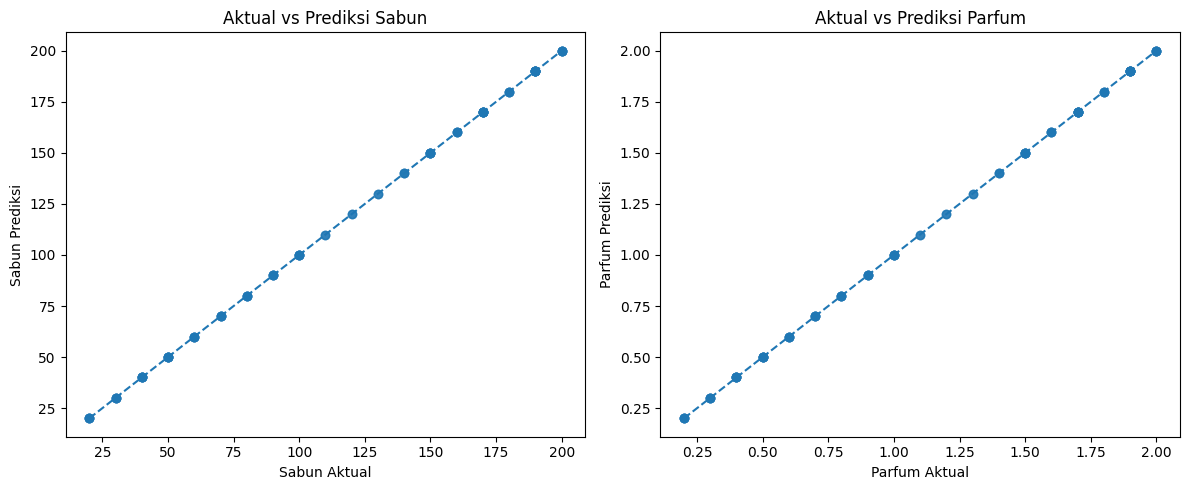

In [29]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, target in enumerate(["sabun", "parfum"]):
    aktual = y_test[target].to_numpy()
    prediksi = y_pred[:, i]

    axes[i].scatter(aktual, prediksi, alpha=0.7)

    batas_min = min(aktual.min(), prediksi.min())
    batas_max = max(aktual.max(), prediksi.max())

    axes[i].plot(
        [batas_min, batas_max],
        [batas_min, batas_max],
        linestyle="--"
    )

    axes[i].set_xlabel(f"{target.title()} Aktual")
    axes[i].set_ylabel(f"{target.title()} Prediksi")
    axes[i].set_title(f"Aktual vs Prediksi {target.title()}")

plt.tight_layout()
plt.show()


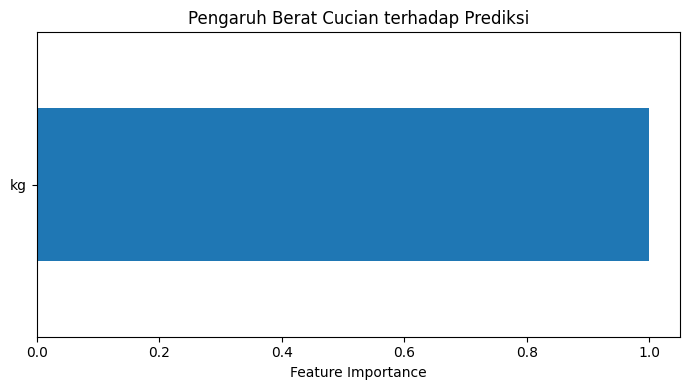

In [30]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(kind="barh", figsize=(7, 4))

plt.xlabel("Feature Importance")
plt.title("Pengaruh Berat Cucian terhadap Prediksi")
plt.tight_layout()
plt.show()

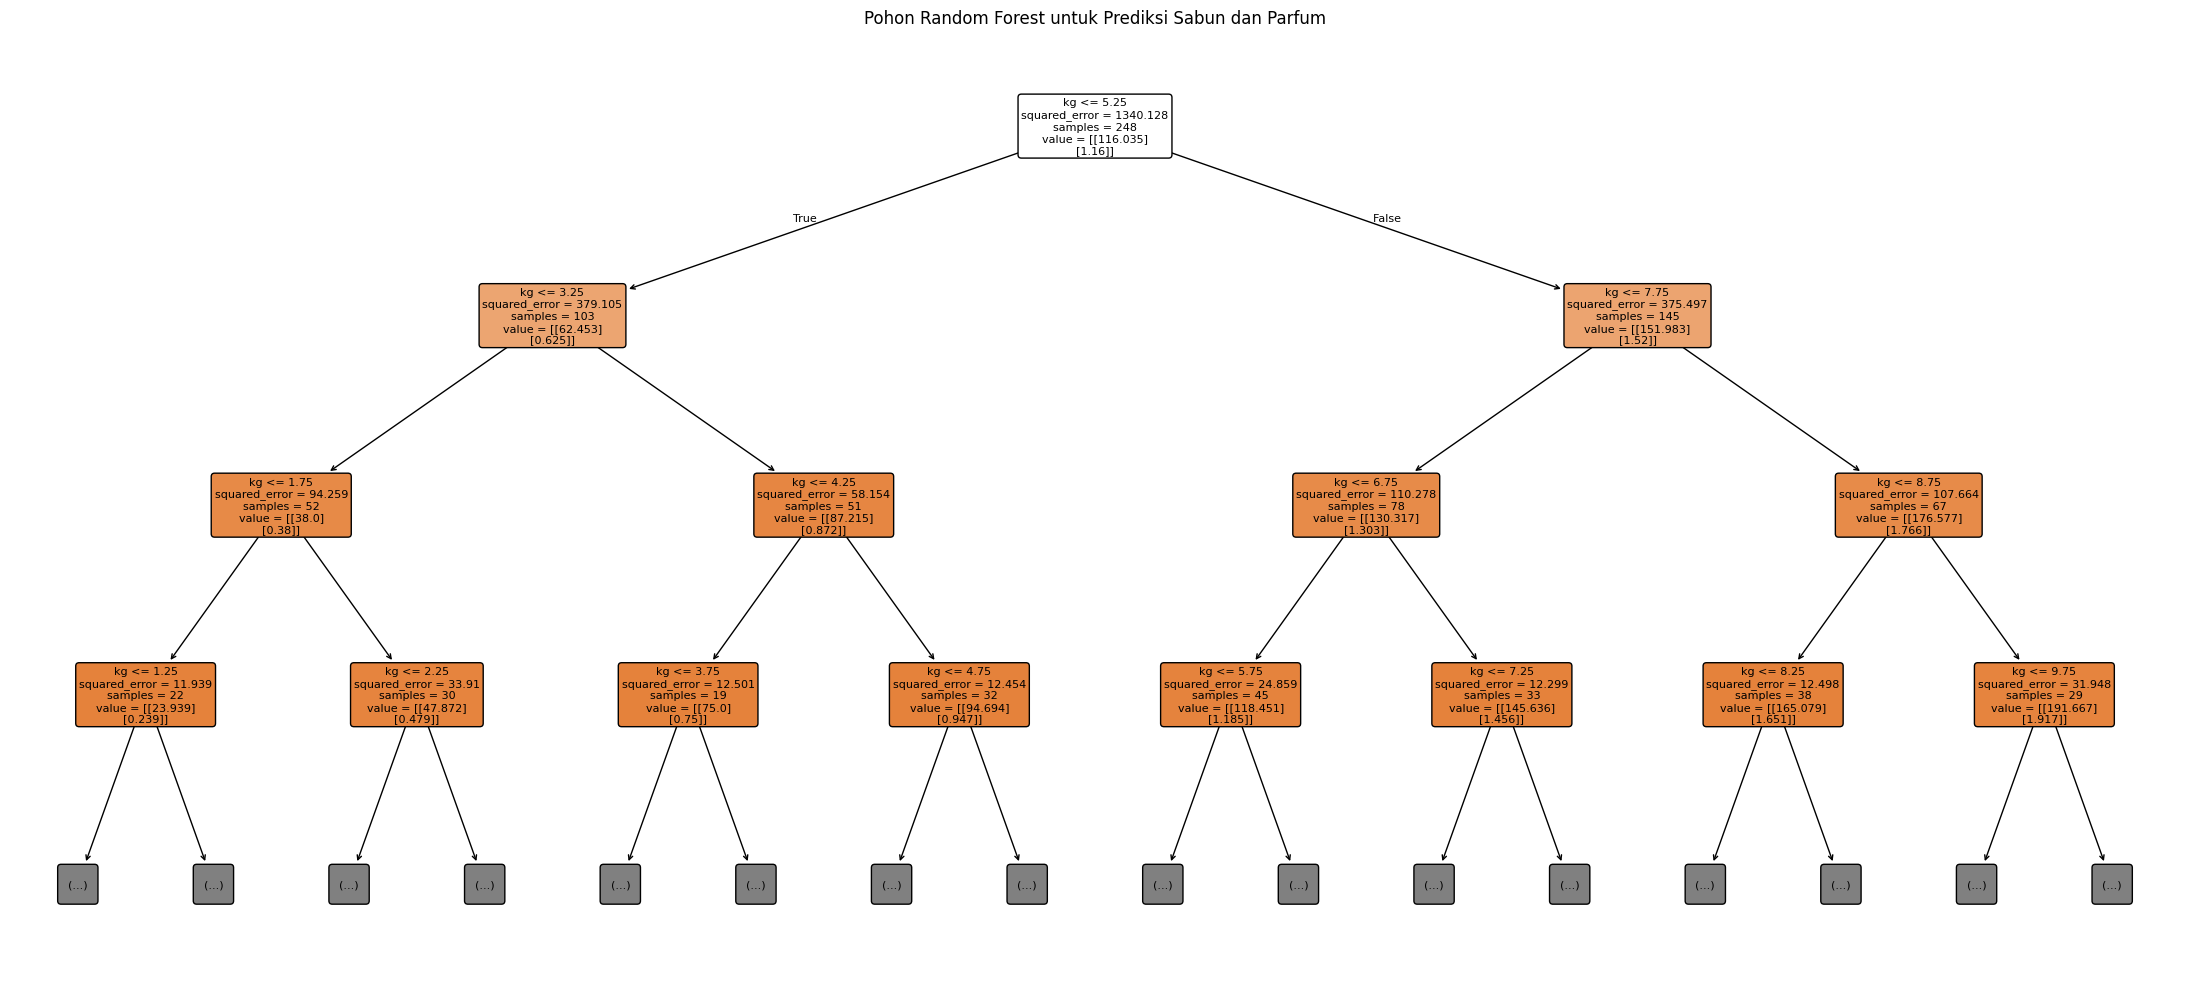

In [31]:
tree = model.estimators_[0]

plt.figure(figsize=(22, 10))

plot_tree(
    tree,
    feature_names=X.columns.tolist(),
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Pohon Random Forest untuk Prediksi Sabun dan Parfum")
plt.tight_layout()
plt.show()

Prediksi data baru

In [44]:

# Contoh: cucian seberat 1 kg
data_baru = pd.DataFrame({
    "kg": [1.0]
})

pred_baru = model.predict(data_baru)[0]

print("\n========== PREDIKSI LAUNDRY ==========")
print(f"Berat cucian : {data_baru.loc[0, 'kg']} kg")
print(f"Prediksi sabun  : {pred_baru[0]:.0f}")
print(f"Prediksi parfum : {pred_baru[1]:.1f}")



========== PREDIKSI LAUNDRY ==========
Berat cucian : 1.0 kg
Prediksi sabun  : 20
Prediksi parfum : 0.2


Kesimpulan

In [33]:
print("\n========== KESIMPULAN ==========")
print(f"Total data: {len(data)}")

print(
    "Model memprediksi kebutuhan sabun dan parfum "
    "berdasarkan berat cucian."
)


========== KESIMPULAN ==========
Total data: 495
Model memprediksi kebutuhan sabun dan parfum berdasarkan berat cucian.


Ubah KE file PKL

In [34]:
save_dict = {
    "model": model,
    "feature_names": ["kg"],
    "target_names": ["sabun", "parfum"]
}

with open("random_forest_laundry.pkl", "wb") as file:
    pickle.dump(save_dict, file)

print("\nModel berhasil disimpan:")
print("random_forest_laundry.pkl")


Model berhasil disimpan:
random_forest_laundry.pkl
